# Nairobi Delivery Time Prediction — Multivariate Regression

**Mission:** Make last-mile delivery reliable and affordable across East Africa so small businesses can grow.

**Use case:** Predict how long a motorbike delivery in Nairobi will take, from the moment the rider picks up the parcel to arrival at the customer (in minutes).

**Who uses the prediction and for what:** Delivery platforms such as Sendy show this estimate to the business and its customer as an accurate arrival time, and use it to plan which rider takes which order. Accurate ETAs build trust and cut wasted waiting time.

**Dataset:** Sendy Logistics Challenge (Zindi) — 21,201 real, anonymised Nairobi orders plus statistics for 960 riders.
Source: https://zindi.africa/competitions/sendy-logistics-challenge/data

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Load and merge the data
The orders file and the riders file share the `Rider Id` column, so each order gets its rider's experience and rating attached.

In [25]:
orders = pd.read_csv("Train.csv")
riders = pd.read_csv("Riders.csv")

# Each order has a Rider Id, so we attach that rider's statistics to the order
df = orders.merge(riders, on="Rider Id", how="left")

print("Orders:", orders.shape)
print("Riders:", riders.shape)
print("Merged:", df.shape)
print("Orders with no matching rider:", df["No_Of_Orders"].isna().sum())

Orders: (21201, 29)
Riders: (960, 5)
Merged: (21201, 33)
Orders with no matching rider: 0


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21201 entries, 0 to 21200
Data columns (total 33 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Order No                                   21201 non-null  str    
 1   User Id                                    21201 non-null  str    
 2   Vehicle Type                               21201 non-null  str    
 3   Platform Type                              21201 non-null  int64  
 4   Personal or Business                       21201 non-null  str    
 5   Placement - Day of Month                   21201 non-null  int64  
 6   Placement - Weekday (Mo = 1)               21201 non-null  int64  
 7   Placement - Time                           21201 non-null  str    
 8   Confirmation - Day of Month                21201 non-null  int64  
 9   Confirmation - Weekday (Mo = 1)            21201 non-null  int64  
 10  Confirmation - Time              

In [27]:
missing = df.isna().sum()
print((missing[missing > 0] / len(df) * 100).round(1).astype(str) + " % missing")
print()
print(df["Vehicle Type"].value_counts())
print()
print(df["Platform Type"].value_counts())
print()
print(df["Personal or Business"].value_counts())

Temperature                     20.6 % missing
Precipitation in millimeters    97.4 % missing
dtype: str

Vehicle Type
Bike    21201
Name: count, dtype: int64

Platform Type
3    18054
1     2147
2      980
4       20
Name: count, dtype: int64

Personal or Business
Business    17384
Personal     3817
Name: count, dtype: int64


**What this shows:** Precipitation is 97% missing and Temperature 21% missing. Every order uses a bike, so `Vehicle Type` carries no information. Note also that the rider column `Age` means *days since the rider's first delivery* (experience), not the rider's age in years.

## 2. Feature engineering: new columns
- **Pickup Hour** is pulled from the pickup time, because traffic in Nairobi depends on the time of day.
- **Delivery Time (min)** is the target, converted from seconds to minutes so the errors are easy to read.

In [28]:
# Pickup hour: the time of day the rider collected the parcel (rush hour vs quiet hours)
df["Pickup Hour"] = pd.to_datetime(df["Pickup - Time"], format="%I:%M:%S %p").dt.hour

# Target in minutes instead of seconds, so errors are easier to read
df["Delivery Time (min)"] = df["Time from Pickup to Arrival"] / 60

df[["Pickup - Time", "Pickup Hour", "Time from Pickup to Arrival", "Delivery Time (min)"]].head()

,Pickup - Time,Pickup Hour,Time from Pickup to Arrival,Delivery Time (min)
0,10:27:30 AM,10,745,12.416667
1,11:44:09 AM,11,1993,33.216667
2,12:53:03 PM,12,455,7.583333
3,9:43:06 AM,9,1341,22.350000
4,10:05:23 AM,10,1214,20.233333


## 3. Exploratory data analysis
### Visualization 1: Distribution of the target

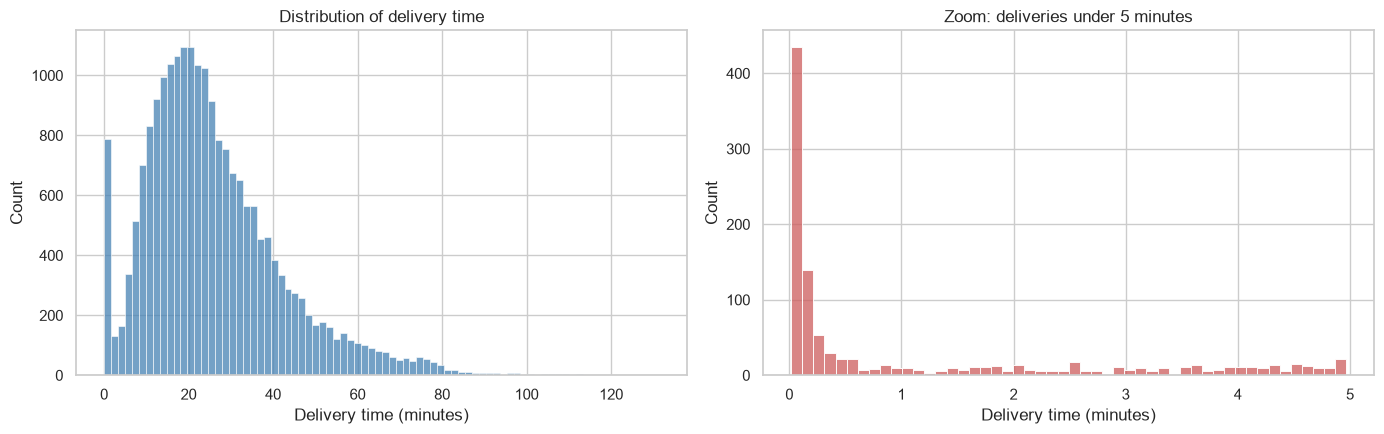

Deliveries under 1 minute: 740


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df["Delivery Time (min)"], bins=80, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of delivery time")
axes[0].set_xlabel("Delivery time (minutes)")

sns.histplot(df.loc[df["Delivery Time (min)"] < 5, "Delivery Time (min)"], bins=50, ax=axes[1], color="indianred")
axes[1].set_title("Zoom: deliveries under 5 minutes")
axes[1].set_xlabel("Delivery time (minutes)")

plt.tight_layout()
plt.show()

print("Deliveries under 1 minute:", (df["Delivery Time (min)"] < 1).sum())

**What it shows:** Most deliveries take 10–40 minutes (median ≈ 23 min) with a long right tail up to about 2 hours. There is also an unrealistic spike close to 0 minutes: 740 orders were "delivered" in under 1 minute, which is impossible across Nairobi. These are riders tapping *arrived* by mistake.

**Decision:** Remove the 740 orders under 1 minute, because they are data-entry errors that would teach the model wrong patterns. The long right tail is real (traffic, long trips), so it stays.

In [30]:
before = len(df)
df = df[df["Delivery Time (min)"] >= 1].copy()
print(f"Removed {before - len(df)} impossible deliveries. Rows left: {len(df)}")

Removed 740 impossible deliveries. Rows left: 20461


### Visualization 2: Correlation heatmap

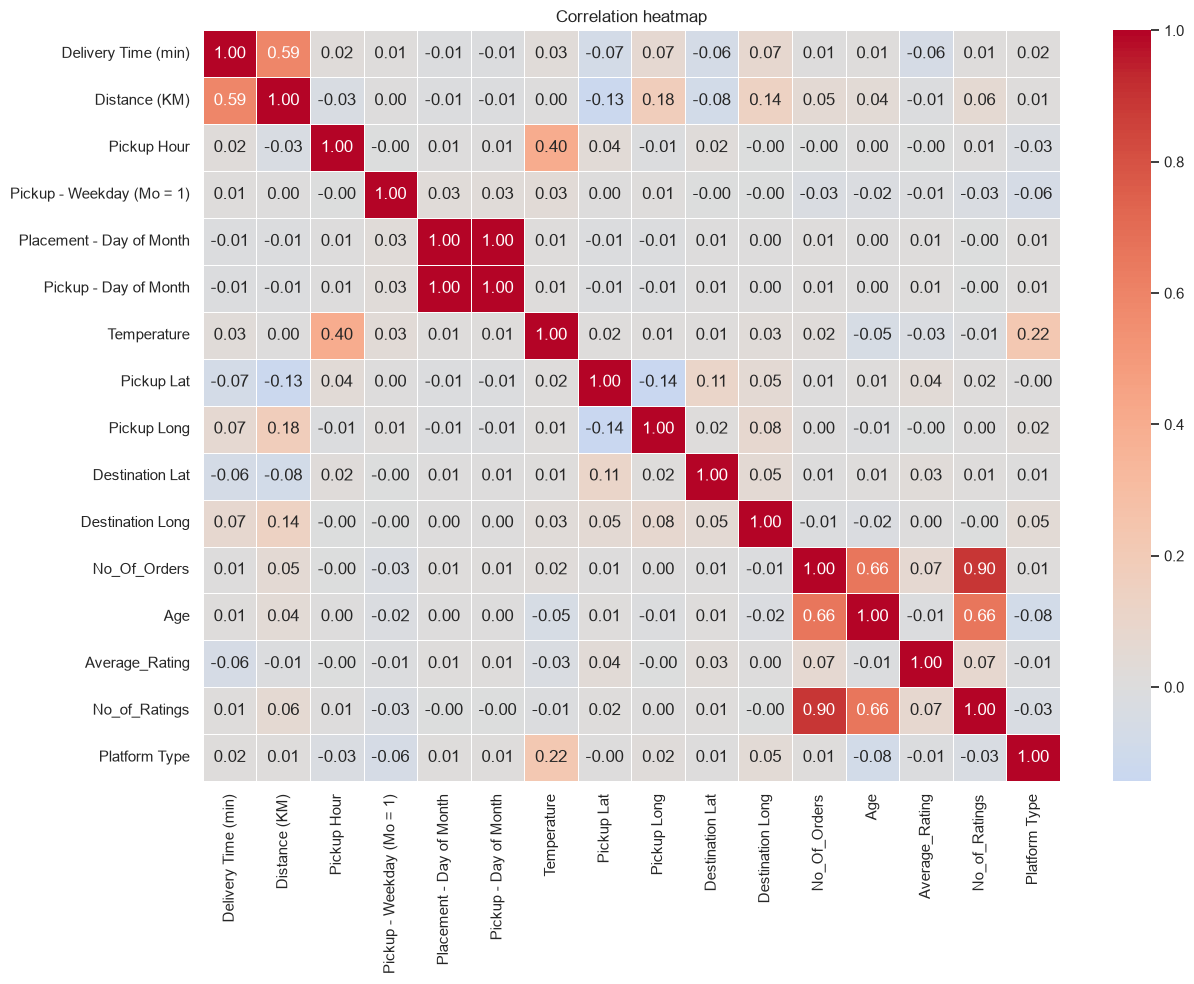

Distance (KM)                0.586
Destination Long             0.072
Pickup Long                  0.069
Pickup Lat                  -0.068
Destination Lat             -0.063
Average_Rating              -0.062
Temperature                  0.027
Pickup Hour                  0.020
Platform Type                0.015
Age                          0.014
Placement - Day of Month    -0.014
Pickup - Day of Month       -0.014
Pickup - Weekday (Mo = 1)    0.009
No_of_Ratings                0.009
No_Of_Orders                 0.005
Name: Delivery Time (min), dtype: float64


In [31]:
corr_cols = [
    "Delivery Time (min)", "Distance (KM)", "Pickup Hour", "Pickup - Weekday (Mo = 1)",
    "Placement - Day of Month", "Pickup - Day of Month", "Temperature",
    "Pickup Lat", "Pickup Long", "Destination Lat", "Destination Long",
    "No_Of_Orders", "Age", "Average_Rating", "No_of_Ratings", "Platform Type",
]
corr = df[corr_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

print(corr["Delivery Time (min)"].drop("Delivery Time (min)").sort_values(key=abs, ascending=False).round(3))

**What it shows:** **Distance (KM)** is by far the strongest predictor of delivery time (r ≈ 0.59). Every other column has a weak *linear* correlation (|r| < 0.08). `No_Of_Orders` and `No_of_Ratings` are strongly correlated with each other (r ≈ 0.90), so they carry the same information. `Placement - Day of Month` and `Pickup - Day of Month` are identical copies (r = 1.00).

**Decisions:**
- Distance is the key feature, and it will be used for the before/after scatter plots.
- Drop `No_of_Ratings` (it duplicates `No_Of_Orders`) and all the repeated day/weekday columns, keeping only `Pickup - Weekday`.
- Keep the coordinates, pickup hour and rider stats even though their linear correlation is weak: traffic zones and rush hours affect time *non-linearly*, which tree models can still learn.
- Drop `Temperature`: 21% missing and almost no relationship with the target (r ≈ 0.03).

### Visualization 3: Distance distribution and categorical features

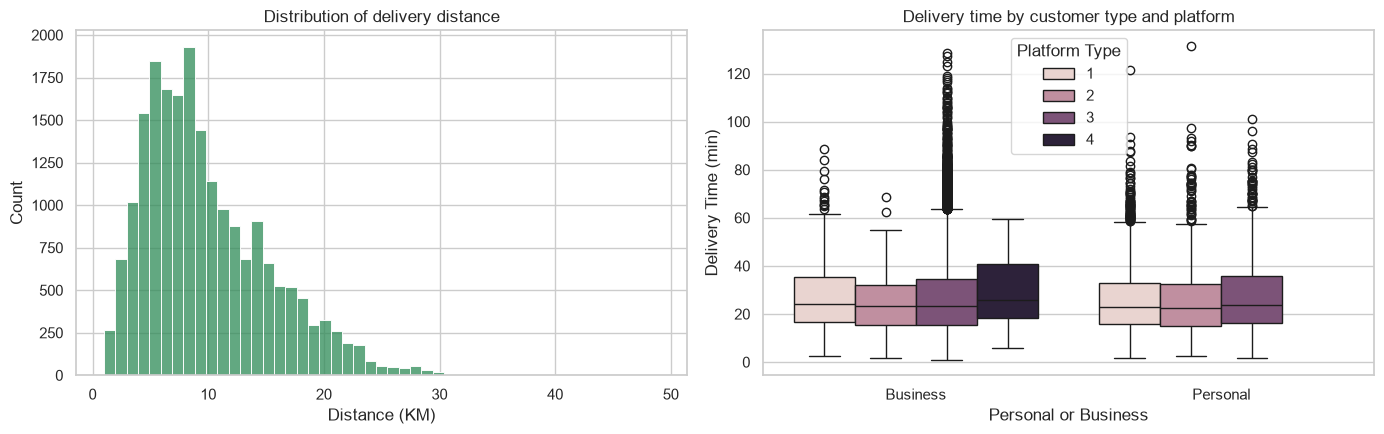

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df["Distance (KM)"], bins=49, ax=axes[0], color="seagreen")
axes[0].set_title("Distribution of delivery distance")

sns.boxplot(data=df, x="Personal or Business", y="Delivery Time (min)", hue="Platform Type", ax=axes[1])
axes[1].set_title("Delivery time by customer type and platform")

plt.tight_layout()
plt.show()

**What it shows:** Most trips are 3–15 km, with a few up to 49 km, all realistic for Nairobi. The categorical columns shift delivery time only slightly: platform 4 orders take a little longer, and business and personal orders are similar.

**Decision:** Keep `Platform Type` and `Personal or Business` as categorical features (converted to numbers with one-hot encoding). The effect is small but real, and it costs the model almost nothing to include them. Distance values are realistic, which later guides the API range (1–50 km).

## 4. Feature selection summary

| Dropped column(s) | Reason |
|---|---|
| Order No, User Id, Rider Id | Identifiers, no predictive meaning |
| Vehicle Type | Only one value (Bike) |
| Arrival at Destination (day, weekday, time) | **Data leakage**: these reveal the answer |
| Placement / Confirmation / Arrival at Pickup columns | Their day and weekday are copies of the pickup ones (r = 1.00), and their times describe steps before the trip starts |
| Pickup - Day of Month, Pickup - Time | Day of month has no link to delivery time (r = −0.01); the time is replaced by the engineered Pickup Hour |
| Precipitation in millimeters | 97% missing |
| Temperature | 21% missing, no correlation with the target |
| No_of_Ratings | Duplicates No_Of_Orders (r = 0.90) |
| Time from Pickup to Arrival | Original target in seconds (replaced by minutes) |

**Features kept (12):** Distance, Pickup Weekday, Pickup Hour, Pickup Lat/Long, Destination Lat/Long, rider No_Of_Orders, rider Age (days active), rider Average_Rating, Platform Type, Personal or Business. **Distance matters most.**

In [33]:
numeric_features = [
    "Distance (KM)", "Pickup - Weekday (Mo = 1)", "Pickup Hour",
    "Pickup Lat", "Pickup Long", "Destination Lat", "Destination Long",
    "No_Of_Orders", "Age", "Average_Rating",
]
categorical_features = ["Platform Type", "Personal or Business"]
features = numeric_features + categorical_features
target = "Delivery Time (min)"

X = df[features]
y = df[target]

print("Features used:", len(features))
print(X.dtypes)
X.head()

Features used: 12
Distance (KM)                  int64
Pickup - Weekday (Mo = 1)      int64
Pickup Hour                    int32
Pickup Lat                   float64
Pickup Long                  float64
Destination Lat              float64
Destination Long             float64
No_Of_Orders                   int64
Age                            int64
Average_Rating               float64
Platform Type                  int64
Personal or Business             str
dtype: object


,Distance (KM),Pickup - Weekday (Mo = 1),Pickup Hour,Pickup Lat,Pickup Long,Destination Lat,Destination Long,No_Of_Orders,Age,Average_Rating,Platform Type,Personal or Business
0,4,5,10,-1.317755,36.830370,-1.300406,36.829741,1637,1309,13.8,3,Business
1,16,5,11,-1.351453,36.899315,-1.295004,36.814358,396,339,13.6,3,Personal
2,3,2,12,-1.308284,36.843419,-1.300921,36.828195,1023,242,12.5,3,Business
3,9,5,9,-1.281301,36.832396,-1.257147,36.795063,886,283,14.5,3,Business
4,9,1,10,-1.266597,36.792118,-1.295041,36.809817,2311,872,14.1,1,Personal


## 5. Encode categorical columns, split, then standardize
- **One-hot encoding** turns `Platform Type` (1–4) and `Personal or Business` into 0/1 columns, so the models only see numbers.
- **Split first (80% train / 20% test), then scale.** The scaler is fitted on the **training set only** and then applied to the test set. If it also learned the mean and standard deviation of the test data, information from the "exam" would leak into training and the test MSE would look better than it really is.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

X_train_prep = preprocessor.fit_transform(X_train)   # learns mean/std and categories from TRAIN only
X_test_prep = preprocessor.transform(X_test)          # re-uses what it learned, never looks at test

encoded_names = preprocessor.get_feature_names_out()
print("Train:", X_train.shape, "->", X_train_prep.shape)
print("Test: ", X_test.shape, "->", X_test_prep.shape)
print("Columns after encoding:", list(encoded_names))
pd.DataFrame(X_train_prep[:5], columns=encoded_names).round(2)

Train: (16368, 12) -> (16368, 16)
Test:  (4093, 12) -> (4093, 16)
Columns after encoding: ['num__Distance (KM)', 'num__Pickup - Weekday (Mo = 1)', 'num__Pickup Hour', 'num__Pickup Lat', 'num__Pickup Long', 'num__Destination Lat', 'num__Destination Long', 'num__No_Of_Orders', 'num__Age', 'num__Average_Rating', 'cat__Platform Type_1', 'cat__Platform Type_2', 'cat__Platform Type_3', 'cat__Platform Type_4', 'cat__Personal or Business_Business', 'cat__Personal or Business_Personal']


,num__Distance (KM),num__Pickup - Weekday (Mo = 1),num__Pickup Hour,num__Pickup Lat,num__Pickup Long,num__Destination Lat,num__Destination Long,num__No_Of_Orders,num__Age,num__Average_Rating,cat__Platform Type_1,cat__Platform Type_2,cat__Platform Type_3,cat__Platform Type_4,cat__Personal or Business_Business,cat__Personal or Business_Personal
0,-0.99,-1.44,0.06,-0.93,0.86,-0.63,0.22,-0.14,0.22,0.23,1.0,0.0,0.0,0.0,0.0,1.0
1,-0.11,-0.16,-0.34,0.57,-0.48,-0.51,0.41,-0.99,-1.15,1.19,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.11,0.48,-0.73,0.85,-0.77,-0.14,-1.35,-0.05,0.15,-0.63,0.0,0.0,1.0,0.0,1.0,0.0
3,-0.99,-0.16,-1.12,0.85,-0.77,0.45,-0.38,0.17,0.28,-0.41,0.0,0.0,1.0,0.0,1.0,0.0
4,-0.82,0.48,-1.12,-0.44,-0.86,0.30,-0.35,-0.99,-0.18,0.66,0.0,1.0,0.0,0.0,0.0,1.0


## 6. Model 1 — Linear regression by gradient descent (SGDRegressor)
SGDRegressor learns the line step by step. scikit-learn does not record the loss per epoch, so we train with `partial_fit` in a loop: each call is **one epoch** (one full pass over the training data), and after each one we can measure the train and test MSE.

We tune three hyperparameters, changing one at a time:
- **Learning rate (eta0):** how big each update step is.
- **Regularization strength (alpha):** a penalty on large weights that discourages overfitting.
- **Epochs:** how many passes over the training data.

In [35]:
def train_sgd(learning_rate, alpha, epochs, record=False):
    """Train an SGDRegressor one epoch at a time with partial_fit.
    Returns the model and, if record=True, the train/test MSE after every epoch."""
    model = SGDRegressor(learning_rate="constant", eta0=learning_rate, alpha=alpha, random_state=42)
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        model.partial_fit(X_train_prep, y_train)          # one full pass over the training data
        if record:
            train_losses.append(mean_squared_error(y_train, model.predict(X_train_prep)))
            test_losses.append(mean_squared_error(y_test, model.predict(X_test_prep)))
    return model, train_losses, test_losses

def sgd_scores(model):
    return (mean_squared_error(y_train, model.predict(X_train_prep)),
            mean_squared_error(y_test, model.predict(X_test_prep)))

### Experiment 1: Learning rate (alpha = 0.0001, 50 epochs)

In [36]:
tuning_log = []

for lr in [0.0001, 0.001, 0.01, 0.1]:
    model, _, _ = train_sgd(learning_rate=lr, alpha=0.0001, epochs=50)
    train_mse, test_mse = sgd_scores(model)
    tuning_log.append({"experiment": "learning rate", "learning_rate": lr, "alpha": 0.0001, "epochs": 50,
                       "train_MSE": train_mse, "test_MSE": test_mse})

pd.DataFrame(tuning_log).round({"train_MSE": 2, "test_MSE": 2})

,experiment,learning_rate,alpha,epochs,train_MSE,test_MSE
0,learning rate,0.0001,0.0001,50,166.34,165.71
1,learning rate,0.0010,0.0001,50,167.98,167.06
2,learning rate,0.0100,0.0001,50,186.27,186.39
3,learning rate,0.1000,0.0001,50,1060.08,1029.41


**Result:** The smallest learning rate, **0.0001**, gives the lowest test MSE (165.71). As the learning rate grows, the loss gets worse: 167.06 at 0.001, 186.39 at 0.01, and 1029 at 0.1. Large steps keep overshooting the minimum instead of settling into it. **Decision:** use learning rate 0.0001.

### Experiment 2: Regularization strength (learning rate = 0.0001, 50 epochs)

In [37]:
for alpha in [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0]:
    model, _, _ = train_sgd(learning_rate=0.0001, alpha=alpha, epochs=50)
    train_mse, test_mse = sgd_scores(model)
    tuning_log.append({"experiment": "regularization", "learning_rate": 0.0001, "alpha": alpha, "epochs": 50,
                       "train_MSE": train_mse, "test_MSE": test_mse})

pd.DataFrame(tuning_log[4:]).round({"train_MSE": 2, "test_MSE": 2})

,experiment,learning_rate,alpha,epochs,train_MSE,test_MSE
0,regularization,0.0001,0.00001,50,166.34,165.71
1,regularization,0.0001,0.00010,50,166.34,165.71
2,regularization,0.0001,0.00100,50,166.34,165.72
3,regularization,0.0001,0.01000,50,166.37,165.81
4,regularization,0.0001,0.10000,50,167.36,166.97
5,regularization,0.0001,1.00000,50,190.15,190.10


**Result:** Small alphas (0.00001–0.001) give almost the same test MSE (about 165.7), and stronger regularization makes it worse: 166.97 at 0.1 and 190.10 at 1.0. The train and test MSE are already almost equal, so the linear model is **not overfitting**, and extra penalty only pulls the weights away from the best fit (underfitting). **Decision:** use alpha 0.0001.

### Experiment 3: Number of epochs (learning rate = 0.0001, alpha = 0.0001)

In [38]:
for epochs in [1, 5, 10, 25, 50, 100]:
    model, _, _ = train_sgd(learning_rate=0.0001, alpha=0.0001, epochs=epochs)
    train_mse, test_mse = sgd_scores(model)
    tuning_log.append({"experiment": "epochs", "learning_rate": 0.0001, "alpha": 0.0001, "epochs": epochs,
                       "train_MSE": train_mse, "test_MSE": test_mse})

pd.DataFrame(tuning_log[10:]).round({"train_MSE": 2, "test_MSE": 2})

,experiment,learning_rate,alpha,epochs,train_MSE,test_MSE
0,epochs,0.0001,0.0001,1,182.70,182.97
1,epochs,0.0001,0.0001,5,166.76,166.35
2,epochs,0.0001,0.0001,10,166.45,165.95
3,epochs,0.0001,0.0001,25,166.35,165.76
4,epochs,0.0001,0.0001,50,166.34,165.71
5,epochs,0.0001,0.0001,100,166.34,165.71


**Result:** One epoch is not enough (test MSE 182.97). The loss drops quickly up to about 10 epochs (165.95) and is fully converged by 50 (165.71). Going to 100 epochs changes nothing. **Decision:** 50 epochs.

**Final SGD settings:** learning rate = 0.0001, alpha = 0.0001, epochs = 50.

### Loss curve of the final SGD model

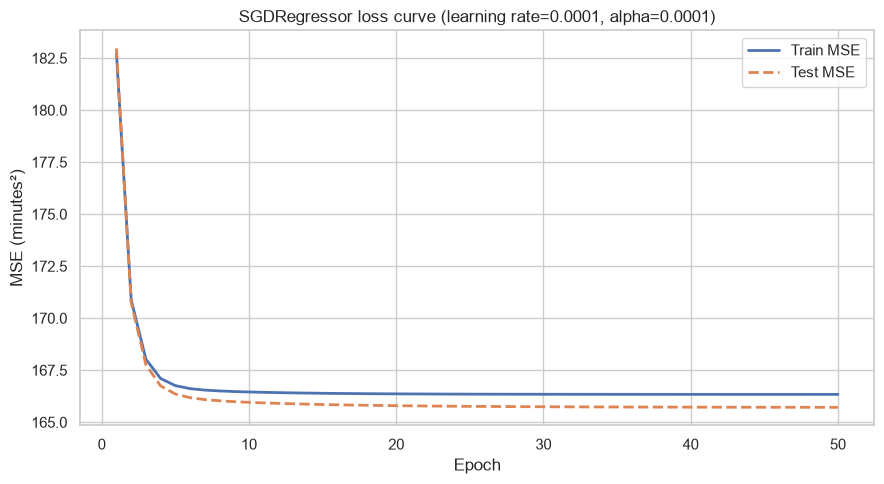

Epoch 1:  train MSE = 182.70, test MSE = 182.97
Epoch 50: train MSE = 166.34, test MSE = 165.71


In [39]:
BEST_LR, BEST_ALPHA, BEST_EPOCHS = 0.0001, 0.0001, 50
sgd_model, sgd_train_losses, sgd_test_losses = train_sgd(BEST_LR, BEST_ALPHA, BEST_EPOCHS, record=True)

plt.figure(figsize=(9, 5))
plt.plot(range(1, BEST_EPOCHS + 1), sgd_train_losses, label="Train MSE", linewidth=2)
plt.plot(range(1, BEST_EPOCHS + 1), sgd_test_losses, label="Test MSE", linewidth=2, linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MSE (minutes²)")
plt.title(f"SGDRegressor loss curve (learning rate={BEST_LR}, alpha={BEST_ALPHA})")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Epoch 1:  train MSE = {sgd_train_losses[0]:.2f}, test MSE = {sgd_test_losses[0]:.2f}")
print(f"Epoch {BEST_EPOCHS}: train MSE = {sgd_train_losses[-1]:.2f}, test MSE = {sgd_test_losses[-1]:.2f}")

**What it shows:** Both losses fall sharply in the first 5 epochs (from about 183 to about 167) and then flatten. The train and test curves stay very close together, so the model generalizes well to unseen orders with no overfitting. Its limit comes from being a straight-line model, not from training too little.

## 7. Models 2–4 — Closed-form linear regression, decision tree, random forest
All three use the same preprocessed training data and are evaluated on the same test set.

In [40]:
lin_model = LinearRegression()
lin_model.fit(X_train_prep, y_train)

for depth in [3, 5, 8, 12, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train_prep, y_train)
    print(f"Decision tree max_depth={depth}: train MSE = {mean_squared_error(y_train, tree.predict(X_train_prep)):.2f}, "
          f"test MSE = {mean_squared_error(y_test, tree.predict(X_test_prep)):.2f}")

tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train_prep, y_train)

forest_model = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10, random_state=42, n_jobs=-1)
forest_model.fit(X_train_prep, y_train)
print("Models trained.")

Decision tree max_depth=3: train MSE = 168.58, test MSE = 168.31
Decision tree max_depth=5: train MSE = 162.26, test MSE = 166.50
Decision tree max_depth=8: train MSE = 141.16, test MSE = 176.61
Decision tree max_depth=12: train MSE = 94.75, test MSE = 220.78
Decision tree max_depth=None: train MSE = 0.12, test MSE = 329.41
Models trained.


**Decision tree depth:** An unlimited tree memorizes the training data (train MSE 0.12) but fails on new orders (test MSE 329.41), which is classic overfitting. Deeper trees overfit more, so we keep **max_depth = 5**, which has the lowest test MSE of the depths tried (166.50; depth 3 gives 168.31).

**Random forest settings:** 100 trees, `max_depth=15` and `min_samples_leaf=10`. Averaging many trees reduces overfitting, and the depth and leaf limits keep each tree from memorizing single orders while keeping the saved model small enough to deploy.

## 8. Model comparison (same test set, MSE in minutes²)

In [41]:
models = {
    "Linear Regression (SGD, gradient descent)": sgd_model,
    "Linear Regression (closed form)": lin_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
}

results = []
for name, model in models.items():
    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, model.predict(X_train_prep)),
        "Test MSE": mean_squared_error(y_test, model.predict(X_test_prep)),
    })

comparison = pd.DataFrame(results).sort_values("Test MSE").reset_index(drop=True)
comparison["Test RMSE (min)"] = np.sqrt(comparison["Test MSE"])

best_name = comparison.loc[0, "Model"]
best_model = models[best_name]

print(f"Best model (lowest test MSE): {best_name}")
comparison.round(2)

Best model (lowest test MSE): Random Forest


,Model,Train MSE,Test MSE,Test RMSE (min)
0,Random Forest,106.99,154.15,12.42
1,Linear Regression (closed form),166.23,165.70,12.87
2,"Linear Regression (SGD, gradient descent)",166.34,165.71,12.87
3,Decision Tree,162.26,166.50,12.90


**Best model: Random Forest**, with the lowest test MSE (**154.15**, an RMSE of about 12.4 minutes).

| Model | Train MSE | Test MSE |
|---|---|---|
| Random Forest | 106.99 | **154.15** |
| Linear Regression (closed form) | 166.23 | 165.70 |
| Linear Regression (SGD) | 166.34 | 165.71 |
| Decision Tree (depth 5) | 162.26 | 166.50 |

**How the dataset shaped these results:**
- **The two linear models are almost identical** (165.70 vs 165.71). Gradient descent converged to the same solution as the exact formula, which confirms the SGD tuning worked. Both are limited because only distance is strongly linear with time.
- **The random forest wins** because the other features (pickup and destination location, pickup hour, rider experience) affect delivery time in non-linear ways, such as traffic zones and rush hours, which straight lines cannot capture but trees can.
- **A single tree** is unstable: shallow trees underfit and deep trees overfit. The forest averages 100 trees to get the benefits of both.
- **No model gets close to zero error**, because delivery time depends on things the data does not record: live traffic, waiting at the customer's gate, and riders marking times late. The forest's gap between train (107) and test (154) MSE shows some overfitting, which is controlled by the leaf and depth limits.

**Criterion for the best model:** the lowest **test** MSE, meaning the best accuracy on orders the model has never seen, which is what matters when a customer gets an ETA.

## 9. Scatter plots: before and after fitting the regression line
Distance is the feature most correlated with delivery time (r ≈ 0.59), so we plot it against the target. For the line, we fit a **one-feature** linear regression on distance only (used for this plot only).

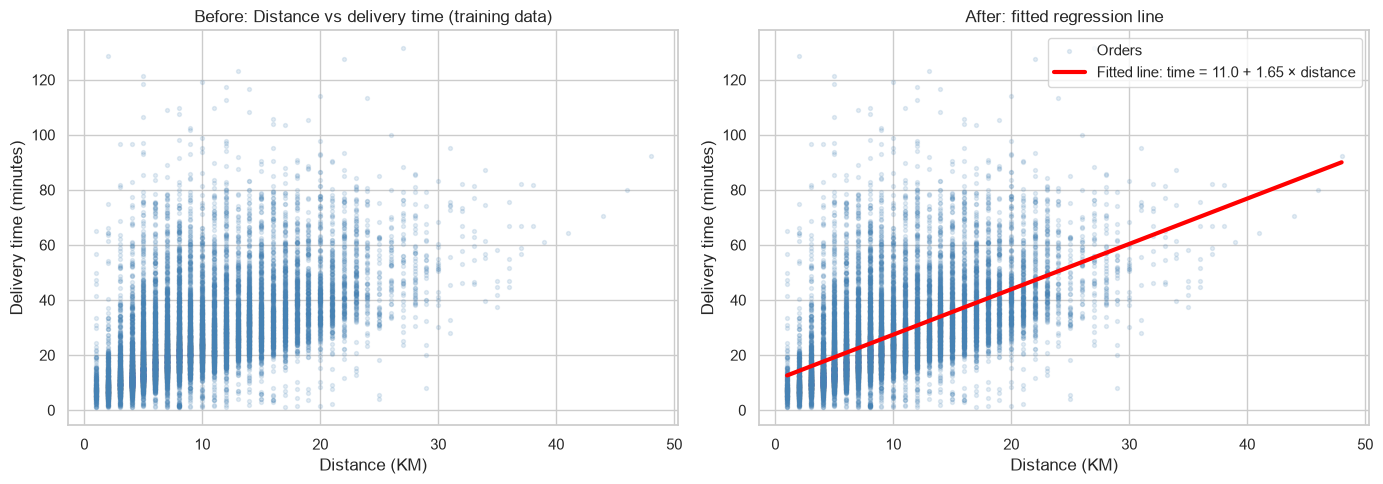

Each extra km adds about 1.65 minutes; base time ≈ 11.0 minutes


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_train["Distance (KM)"], y_train, alpha=0.15, s=8, color="steelblue")
axes[0].set_title("Before: Distance vs delivery time (training data)")
axes[0].set_xlabel("Distance (KM)")
axes[0].set_ylabel("Delivery time (minutes)")

line_model = LinearRegression()
line_model.fit(X_train[["Distance (KM)"]], y_train)

x_line = pd.DataFrame({"Distance (KM)": np.linspace(X_train["Distance (KM)"].min(), X_train["Distance (KM)"].max(), 100)})
y_line = line_model.predict(x_line)

axes[1].scatter(X_train["Distance (KM)"], y_train, alpha=0.15, s=8, color="steelblue", label="Orders")
axes[1].plot(x_line["Distance (KM)"], y_line, color="red", linewidth=3,
             label=f"Fitted line: time = {line_model.intercept_:.1f} + {line_model.coef_[0]:.2f} × distance")
axes[1].set_title("After: fitted regression line")
axes[1].set_xlabel("Distance (KM)")
axes[1].set_ylabel("Delivery time (minutes)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Each extra km adds about {line_model.coef_[0]:.2f} minutes; base time ≈ {line_model.intercept_:.1f} minutes")

**What it shows:** Delivery time rises with distance. The fitted line says each extra kilometre adds about **1.65 minutes**, on top of a base of about **11 minutes** (parking, finding the address, handing over). The wide vertical spread at every distance shows why distance alone is not enough, and why the multi-feature random forest predicts better.

## 10. Save the best model (with its preprocessing)
The saved file is a scikit-learn **Pipeline**: the fitted preprocessor (one-hot encoding plus the scaler fitted on the training set) followed by the trained Random Forest. The API can then send raw input values and the pipeline handles the encoding and scaling itself.

In [43]:
best_pipeline = Pipeline([
    ("preprocessor", preprocessor),   # already fitted on the training set
    ("model", best_model),            # already trained
])

joblib.dump(best_pipeline, "../API/best_model.pkl")
print(f"Saved '{best_name}' pipeline to summative/API/best_model.pkl")

Saved 'Random Forest' pipeline to summative/API/best_model.pkl


## 11. Predict one row of the test set with the saved model
This function loads the saved pipeline from disk and predicts the delivery time for a single order. The API (Task 2) reuses it.

In [44]:
def predict_delivery_time(input_row, model_path="../API/best_model.pkl"):
    """Load the saved pipeline and predict the delivery time (minutes) for one order.
    input_row: a one-row DataFrame with the 12 raw feature columns."""
    pipeline = joblib.load(model_path)
    return float(pipeline.predict(input_row)[0])

one_row = X_test.iloc[[0]]
predicted = predict_delivery_time(one_row)
actual = y_test.iloc[0]

print("Input row:")
print(one_row.T)
print(f"\nPredicted delivery time: {predicted:.1f} minutes")
print(f"Actual delivery time:    {actual:.1f} minutes")

Input row:
                                6491
Distance (KM)                      9
Pickup - Weekday (Mo = 1)          3
Pickup Hour                        9
Pickup Lat                 -1.276574
Pickup Long                36.851365
Destination Lat            -1.252796
Destination Long           36.800313
No_Of_Orders                    2322
Age                              966
Average_Rating                  14.4
Platform Type                      3
Personal or Business        Business

Predicted delivery time: 25.1 minutes
Actual delivery time:    27.6 minutes


## 12. Export data for the API
The API's `/retrain` endpoint refits the Random Forest on the original training data plus any newly uploaded rows, so the training set is saved next to the model. A sample of 300 orders is also saved in the same format, to demonstrate retraining.

In [45]:
train_data = X_train.copy()
train_data[target] = y_train
train_data.to_csv("../API/training_data.csv", index=False)

new_sample = X_test.iloc[:300].copy()
new_sample[target] = y_test.iloc[:300]
new_sample.to_csv("new_data_sample.csv", index=False)

print("Training data saved:", train_data.shape)
print("Sample for /retrain saved:", new_sample.shape)

Training data saved: (16368, 13)
Sample for /retrain saved: (300, 13)
